In [1]:
!pip install -q transformers datasets evaluate accelerate scikit-learn matplotlib seaborn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.4 MB/s eta 0:00:00


# Import dependencies

In [2]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, cohen_kappa_score
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)

import evaluate


# Mount Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Load Cleaned dataset

In [4]:
DATA_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_Cleaned_8987.csv"

df = pd.read_csv(DATA_PATH)

print(df.shape)
df.head()


(8987, 3)


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল,positive
2,2,এখন ভাল ঘৰ এনে হব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো. অৱশেষত দেখিলো. কেৱল...,positive


# Hard Validation Checks

In [5]:
# Remove corrupted row with header leakage
df = df[~((df['ID'] == 4227) & (df['Reviews'] == 'Reviews'))].reset_index(drop=True)

print("Dataset shape after removing corrupted row:", df.shape)


Dataset shape after removing corrupted row: (8986, 3)


In [6]:
assert not ((df['Reviews'] == 'Reviews') | (df['Sentiment'].isna())).any(), \
    "Corrupted rows still exist in the dataset"


# Encode Sentiment Labels

In [7]:
df['Sentiment'] = (
    df['Sentiment']
    .astype(str)
    .str.strip()
    .str.lower()
)

label_map = {'negative': 0, 'positive': 1}
df['label'] = df['Sentiment'].map(label_map)

df = df.dropna(subset=['label']).reset_index(drop=True)

assert df['label'].isna().sum() == 0


# Pre-Tokenization Normalization

In [8]:
# Ensure all reviews are strings (critical for tokenizers)
df['Reviews'] = df['Reviews'].astype(str)

# Remove empty or whitespace-only reviews
df = df[df['Reviews'].str.strip() != ""].reset_index(drop=True)

# Sanity checks
assert df['Reviews'].isna().sum() == 0, "NaN found in Reviews"
assert df['label'].isna().sum() == 0, "NaN found in labels"

print("Pre-tokenization normalization completed")
print("Dataset shape:", df.shape)


Pre-tokenization normalization completed
Dataset shape: (8986, 4)


# Train-Test-Validation Split

In [9]:
train_texts, val_texts, train_labels, val_labels = train_test_split(
    df['Reviews'].tolist(),
    df['label'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

print(len(train_texts), len(val_texts))


7188 1798


In [10]:
# Ensure all reviews are valid strings
df['Reviews'] = df['Reviews'].astype(str)

# Remove empty or invalid text rows (defensive)
df = df[df['Reviews'].str.strip().astype(bool)].reset_index(drop=True)

# Final sanity checks
assert df['Reviews'].isna().sum() == 0, "NaN found in Reviews"
assert df['label'].isna().sum() == 0, "NaN found in labels"
assert df['Reviews'].apply(lambda x: isinstance(x, str)).all(), "Non-string detected"

print("Dataset validated for tokenization")
print("Final dataset shape:", df.shape)


Dataset validated for tokenization
Final dataset shape: (8986, 4)


# Load XLM-Roberta Tokenizer

In [11]:
MODEL_NAME = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [12]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(
    [str(text) for text in train_texts],
    truncation=True,
    padding=True,
    max_length=256
)

val_encodings = tokenizer(
    [str(text) for text in val_texts],
    truncation=True,
    padding=True,
    max_length=256
)


# Tokenization

In [13]:
def tokenize_function(texts):
    return tokenizer(
        [str(t) for t in texts],
        truncation=True,
        padding=False,
        max_length=256
    )

train_encodings = tokenize_function(train_texts)
val_encodings = tokenize_function(val_texts)


# Build Torch Dataset

In [14]:
class AssameseDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = AssameseDataset(train_encodings, train_labels)
val_dataset = AssameseDataset(val_encodings, val_labels)


# Evaluation metrics

In [15]:
accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "macro_f1": f1_score(labels, preds, average="macro"),
        "macro_precision": precision_score(labels, preds, average="macro"),
        "macro_recall": recall_score(labels, preds, average="macro")
    }


# Training Arguments

In [16]:
training_args = TrainingArguments(
    output_dir="./xlmr_results",
    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,          # XLM-R sweet spot
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=5,          # Needs slightly more epochs
    weight_decay=0.01,

    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",

    report_to="none",
    save_total_limit=2
)


# Trainer

In [17]:
data_collator = DataCollatorWithPadding(tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)


/tmp/ipython-input-4200541119.py:3: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


# Training

In [18]:
trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall
1,0.345300,0.272416,0.901557,0.891272,0.905301,0.881756
2,0.226900,0.229591,0.926585,0.922882,0.916261,0.933708
3,0.192600,0.253066,0.937152,0.933396,0.928431,0.939864
4,0.143900,0.209993,0.945495,0.941818,0.939085,0.944891
5,0.087600,0.251443,0.948832,0.945181,0.943848,0.946586


TrainOutput(global_step=2250, training_loss=0.23039193937513563, metrics={'train_runtime': 1044.6443, 'train_samples_per_second': 34.404, 'train_steps_per_second': 2.154, 'total_flos': 1752015406539840.0, 'train_loss': 0.23039193937513563, 'epoch': 5.0})

# Final Evaluation

In [19]:
eval_results = trainer.evaluate()
eval_results


{'eval_loss': 0.25144320726394653,
 'eval_accuracy': 0.9488320355951056,
 'eval_macro_f1': 0.9451812555260831,
 'eval_macro_precision': 0.9438475323521949,
 'eval_macro_recall': 0.9465860495298073,
 'eval_runtime': 11.8236,
 'eval_samples_per_second': 152.069,
 'eval_steps_per_second': 9.557,
 'epoch': 5.0}

In [20]:
import os

CONF_MATRIX_DIR = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/Confusion Matrix/"
RESULTS_DIR = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/"

os.makedirs(CONF_MATRIX_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Result directories ready")


Result directories ready


# Get Predictions

In [21]:
import numpy as np
from scipy.special import softmax

predictions = trainer.predict(val_dataset)

y_true = predictions.label_ids
y_logits = predictions.predictions
y_pred = np.argmax(y_logits, axis=1)
y_probs = softmax(y_logits, axis=1)[:, 1]  # probability for positive class


# Confusion Matrix

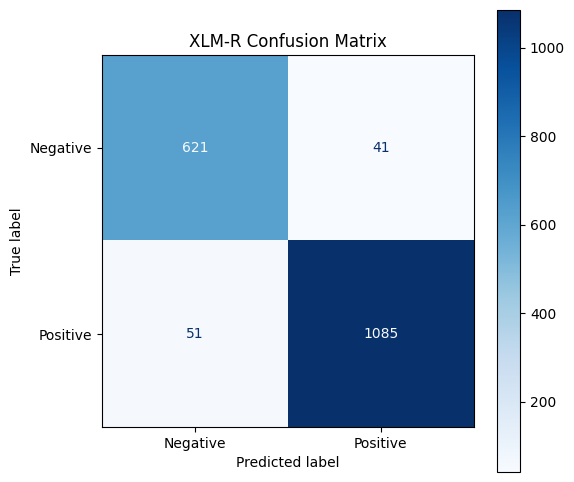

Confusion Matrix saved at: /content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/Confusion Matrix/xlmr_confusion_matrix.svg


In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("XLM-R Confusion Matrix")

# Save as SVG
cm_path = os.path.join(CONF_MATRIX_DIR, "xlmr_confusion_matrix.svg")
plt.savefig(cm_path, format="svg", bbox_inches="tight")

plt.show()

print(f"Confusion Matrix saved at: {cm_path}")


# ROC-AUC Curve and Score

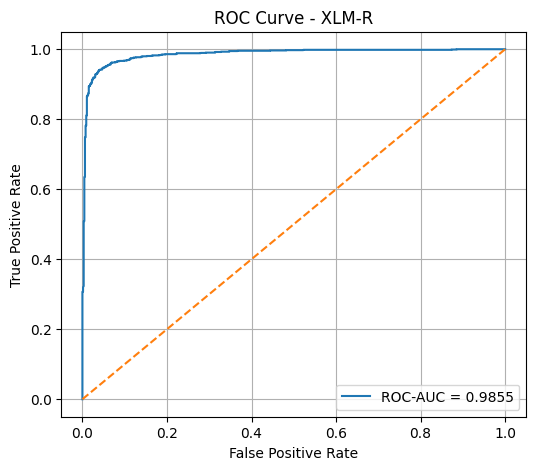

ROC Curve saved at: /content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/xlmr_roc_curve.svg
ROC-AUC Score: 0.9854554061529298


In [23]:
from sklearn.metrics import roc_curve, roc_auc_score

roc_auc = roc_auc_score(y_true, y_probs)
fpr, tpr, _ = roc_curve(y_true, y_probs)

fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve - XLM-R")
ax.legend()
ax.grid(True)

roc_path = os.path.join(RESULTS_DIR, "xlmr_roc_curve.svg")
plt.savefig(roc_path, format="svg", bbox_inches="tight")

plt.show()

print(f"ROC Curve saved at: {roc_path}")


print("ROC-AUC Score:", roc_auc)

# Cohen's Kappa Score

In [24]:
from sklearn.metrics import cohen_kappa_score

kappa = cohen_kappa_score(y_true, y_pred)

print("Cohen's Kappa:", kappa)


Cohen's Kappa: 0.8903661443103279


# Training vs Validation Curves

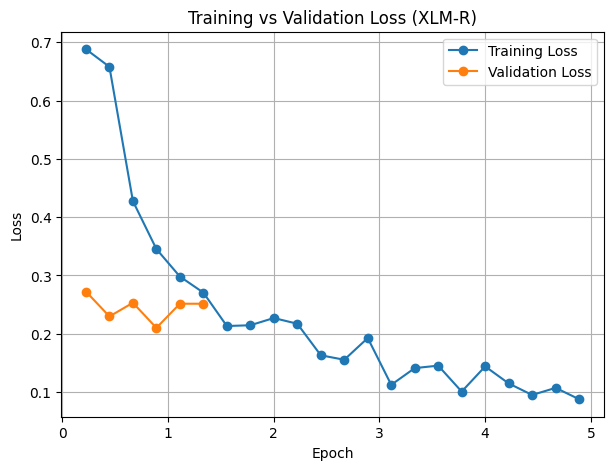

Training vs Validation curve saved at: /content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/xlmr_training_validation_loss.svg


In [25]:
train_loss = []
eval_loss = []
epochs = []

for log in trainer.state.log_history:
    if "loss" in log and "epoch" in log:
        train_loss.append(log["loss"])
        epochs.append(log["epoch"])
    if "eval_loss" in log:
        eval_loss.append(log["eval_loss"])

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(epochs[:len(train_loss)], train_loss, label="Training Loss", marker="o")
ax.plot(epochs[:len(eval_loss)], eval_loss, label="Validation Loss", marker="o")

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Training vs Validation Loss (XLM-R)")
ax.legend()
ax.grid(True)

# Save as SVG
loss_curve_path = os.path.join(RESULTS_DIR, "xlmr_training_validation_loss.svg")
plt.savefig(loss_curve_path, format="svg", bbox_inches="tight")

plt.show()

print(f"Training vs Validation curve saved at: {loss_curve_path}")


# Final Evaluation Metrics Table

In [26]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {
    "Model": "XLM-R",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(y_true, y_pred, average="macro"),
    "Macro Recall": recall_score(y_true, y_pred, average="macro"),
    "Macro F1": f1_score(y_true, y_pred, average="macro"),
    "ROC-AUC": roc_auc,
    "Cohen's Kappa": kappa
}

xlmr_results_df = pd.DataFrame([results])
xlmr_results_df


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC,Cohen's Kappa
0,XLM-R,0.948832,0.943848,0.946586,0.945181,0.985455,0.890366


# Save the Model

In [27]:
MODEL_SAVE_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Models/xlmr/XLM-R-finetuned/"

os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

trainer.save_model(MODEL_SAVE_PATH)
tokenizer.save_pretrained(MODEL_SAVE_PATH)

os.listdir(MODEL_SAVE_PATH)


['config.json',
 'model.safetensors',
 'tokenizer_config.json',
 'special_tokens_map.json',
 'sentencepiece.bpe.model',
 'tokenizer.json',
 'training_args.bin']